# B2: Citra, Ruang Warna, Sampling dan Kuantisasi
SIMUTEH | SEED = 1013 | NIM 2330511013

In [1]:
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

## Langkah 2.3 Kanal warna (Kode 2.1)

KB kanal B   : 1.41
KB kanal G   : 1.87
KB kanal R   : 9.42
KB kanal Gray: 4.89
KB kanal H   : 6.36
KB kanal S   : 0.35
KB kanal V   : 3.46


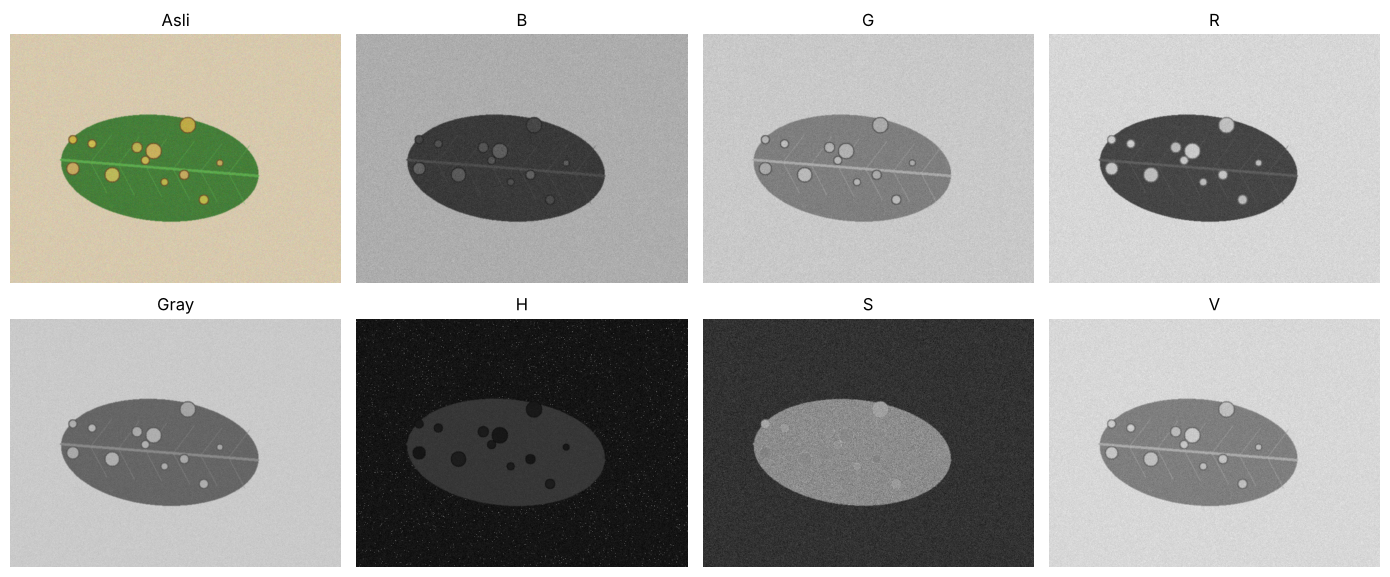

In [2]:
nama = "teh_041.png"                 # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
plt.savefig("../hasil/b2_delapan_kanal.png")
for nm, c_ in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c_, md, mb):.2f}")

## Langkah 2.4 Sampling dan kuantisasi (Kode 2.2)

fx=0.5:  ukuran (240, 320), KB=5.32
fx=0.2:  ukuran (96, 128), KB=4.45
fx=0.1:  ukuran (48, 64), KB=3.01
fx=0.05:  ukuran (24, 32), KB=1.15
k=1: 2 level, KB=3.67
k=2: 3 level, KB=3.67
k=3: 6 level, KB=3.13
k=4: 11 level, KB=4.57
k=8: 153 level, KB=4.89


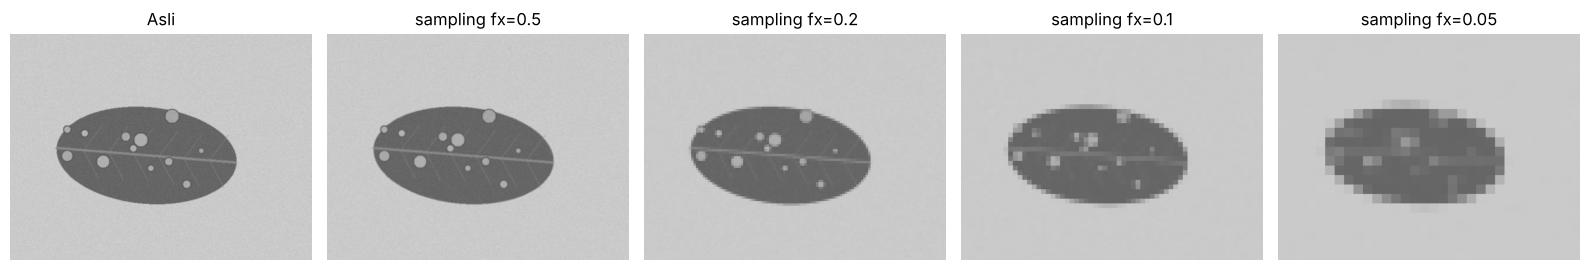

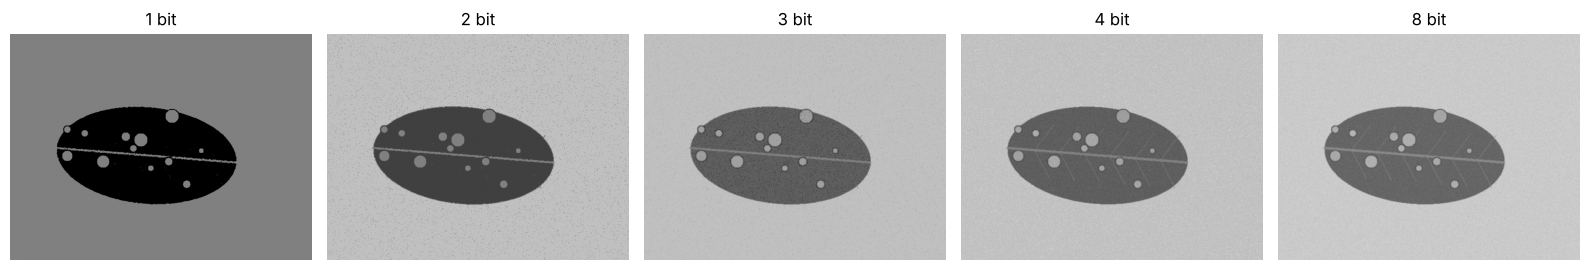

In [3]:
# sampling: perkecil lalu perbesar kembali ke ukuran semula
hasil_s = []
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1],
                       interpolation=cv2.INTER_NEAREST)
    kb = kontras_bercak(besar, md, mb)
    hasil_s.append((fx, kecil.shape, besar))
    print(f"fx={fx}:  ukuran {kecil.shape}, KB={kb:.2f}")

# kuantisasi: sisakan k bit
hasil_k = []
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    hasil_k.append((k, kuant))
    print(f"k={k}: {len(np.unique(kuant))} level, "
          f"KB={kontras_bercak(kuant, md, mb):.2f}")

tampil([gray] + [x[2] for x in hasil_s],
       ["Asli"] + [f"sampling fx={x[0]}" for x in hasil_s], ukuran=(16, 3))
plt.savefig("../hasil/b2_sampling.png")
tampil([x[1] for x in hasil_k], [f"{x[0]} bit" for x in hasil_k], ukuran=(16, 3))
plt.savefig("../hasil/b2_kuantisasi.png")

## Langkah 2.5 KB rata-rata per kanal dan kondisi, kelas berat (Kode 2.3)

In [4]:
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

def tabel_kb(kelas):
    label = pd.read_csv("../data/sintetis/label.csv")
    baris = []
    for _, d in label[label.kelas == kelas].iterrows():
        im = baca(f"../data/sintetis/citra/{d.nama_file}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
        kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
        kb["kondisi"] = d.kondisi_cahaya
        baris.append(kb)
    return pd.DataFrame(baris).groupby("kondisi").mean().round(2)

urut = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
tabel_berat = tabel_kb("berat").loc[urut]
print(tabel_berat)
tabel_berat.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
normal          1.74  1.10   9.07  4.55  6.57  1.06  2.53
gelap           1.69  1.34  10.42  4.55  6.21  1.17  3.09
terang          2.21  0.50   6.89  3.55  5.45  1.05  1.69
kontras_rendah  0.71  0.88   4.05  2.58  1.75  0.38  1.95
bayangan        1.11  0.52   5.10  1.79  4.12  0.46  1.27


## Langkah 2.6 Kelas ringan dan panel kanal terbaik

In [5]:
tabel_ringan = tabel_kb("ringan").loc[urut]
print(tabel_ringan)
tabel_ringan.to_csv("../hasil/b2_kb_kanal_ringan.csv")
print("\nKanal terbaik rata-rata (berat):", tabel_berat.mean().idxmax(), "| (ringan):", tabel_ringan.mean().idxmax())
print("Rata-rata KB semua kondisi (berat):\n", tabel_berat.mean().round(2).to_dict())

                   B     G     R  Gray     H     S     V
kondisi                                                 
normal          2.13  0.67  9.94  3.57  9.15  1.73  1.39
gelap           1.00  1.31  8.29  3.22  5.75  0.87  1.92
terang          1.13  0.19  5.25  2.22  4.51  0.71  0.71
kontras_rendah  0.79  0.35  3.22  1.50  1.89  0.27  0.91
bayangan        1.66  0.53  6.52  1.96  6.33  1.11  1.14

Kanal terbaik rata-rata (berat): R | (ringan): R
Rata-rata KB semua kondisi (berat):
 {'B': 1.49, 'G': 0.87, 'R': 7.11, 'Gray': 3.4, 'H': 4.82, 'S': 0.82, 'V': 2.11}


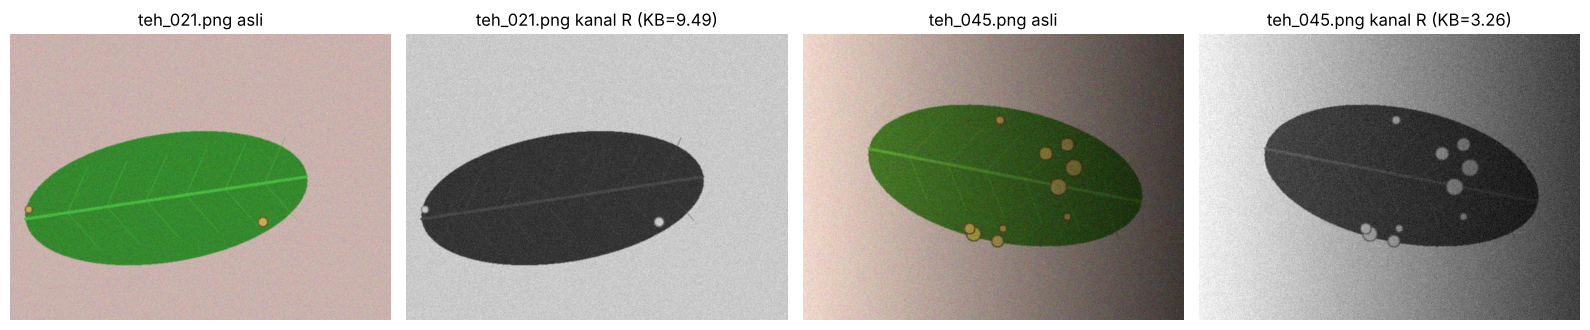

In [6]:
# panel kanal terbaik untuk teh_021 (ringan, normal) dan teh_045 (berat, bayangan)
terbaik = tabel_berat.mean().idxmax()
tampil_list, judul = [], []
for nm in ["teh_021.png", "teh_045.png"]:
    im = baca(f"../data/sintetis/citra/{nm}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    ch = semua_kanal(im)[terbaik]
    tampil_list += [im, ch]
    judul += [f"{nm} asli", f"{nm} kanal {terbaik} (KB={kontras_bercak(ch, m_d, m_b):.2f})"]
tampil(tampil_list, judul, ukuran=(16, 3.5))
plt.savefig("../hasil/b2_panel_terbaik.png")